# **Carga y descripción del dataset**

In [1]:
#Section to import all the libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Adding library to get norm curve for the data
from scipy.stats import norm
#Adding library to display dataframe data
from IPython.display import display

from pathlib import Path
import sys

project_root = Path.cwd().parent  # from Proyecto\notebooks, this is Proyecto
sys.path.insert(0, str(project_root))

from mibici.config import CONFIG

2026-10-15 20:32:21.014 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: E:\GitHub\TC5061-Proyecto-Equipo29


In [2]:
#Loading the data from the CSV file, taking file name and path from the config.py file
def load_data_from_csv():
    file_path = CONFIG.PROCESSED_DATA_DIR / CONFIG.OUTPUT_FILENAME
    dataframe = pd.read_csv(file_path)

    return dataframe

df = load_data_from_csv()

# Use method shape to get rows and column numbers
print(f"Tamaño del DataFrame:", df.shape)
print(f"\n")

# Use method info from pandas to get summary types
print(f"Utilizando método info() para obtener un resumen de los tipos:")
display(df.info())

# Print first 5 rows to verify data
print(f"Utilizando método head() para obtener los primeros 5 registros del dataframe:")
display(df.head(5))

# Get numerical and categorical columns number which will be useful for graphics
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols  = df.select_dtypes(include=['str', 'category']).columns.tolist()

print(f"Columnas númericas: ", num_cols)
print(f"Columnas categoricas: ", cat_cols)

Tamaño del DataFrame: (3362065, 16)


Utilizando método info() para obtener un resumen de los tipos:
<class 'pandas.DataFrame'>
RangeIndex: 3362065 entries, 0 to 3362064
Data columns (total 16 columns):
 #   Column               Dtype  
---  ------               -----  
 0   Viaje_Id             int64  
 1   Usuario_Id           int64  
 2   Genero               str    
 3   Año_de_nacimiento    float64
 4   Inicio_del_viaje     str    
 5   Fin_del_viaje        str    
 6   Origen_Id            int64  
 7   Destino_Id           int64  
 8   origen_nombre        str    
 9   origen_latitud       float64
 10  origen_longitud      float64
 11  origen_dpcapacidad   float64
 12  destino_nombre       str    
 13  destino_latitud      float64
 14  destino_longitud     float64
 15  destino_dpcapacidad  float64
dtypes: float64(7), int64(4), str(5)
memory usage: 804.3 MB


None

Utilizando método head() para obtener los primeros 5 registros del dataframe:


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,origen_nombre,origen_latitud,origen_longitud,origen_dpcapacidad,destino_nombre,destino_latitud,destino_longitud,destino_dpcapacidad
0,42349943,1726166,M,1967.0,2026-01-01 00:03:07,2026-01-01 00:03:39,64,64,(GDL-062) C. Libertad / C. Moscú,20.673072,-103.365055,15.0,(GDL-062) C. Libertad / C. Moscú,20.673072,-103.365055,15.0
1,42349944,1726166,M,1967.0,2026-01-01 00:04:05,2026-01-01 00:13:20,64,35,(GDL-062) C. Libertad / C. Moscú,20.673072,-103.365055,15.0,(GDL-033) Av. Hidalgo / C. Pedro Loza,20.677419,-103.347983,15.0
2,42349945,667524,M,1994.0,2026-01-01 00:05:24,2026-01-01 00:33:40,345,70,(ZPN-075) C. Arquitectos / Av. Guadalupe,20.662344,-103.424764,15.0,(GDL-068) C. Guadalupe Zuno / Av. Chapultepec,20.670512,-103.368306,19.0
3,42349946,534776,M,1978.0,2026-01-01 00:05:48,2026-01-01 00:30:54,35,333,(GDL-033) Av. Hidalgo / C. Pedro Loza,20.677419,-103.347983,15.0,(GDL-239) Silvestre Revueltas Fray Antonio A,20.691247,-103.348064,19.0
4,42349947,161552,M,1997.0,2026-01-01 00:07:07,2026-01-01 00:14:56,268,226,(GDL-195) C. Ramón Corona / Av. Juárez,20.675290,-103.346560,23.0,(GDL-159) C. Guadalupe Victoria /Del Ejercito,20.664680,-103.333570,19.0


Columnas númericas:  ['Viaje_Id', 'Usuario_Id', 'Año_de_nacimiento', 'Origen_Id', 'Destino_Id', 'origen_latitud', 'origen_longitud', 'origen_dpcapacidad', 'destino_latitud', 'destino_longitud', 'destino_dpcapacidad']
Columnas categoricas:  ['Genero', 'Inicio_del_viaje', 'Fin_del_viaje', 'origen_nombre', 'destino_nombre']


# **EDA**

**************************************************
** Datos numericos -- Estadisticas descriptivas **
**************************************************
** Estadisticas descriptivas del dataframe para sus valores numéricos **



,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Viaje_Id,3362065.0,4.431106e+07,1.140699e+06,4.234994e+07,4.330782e+07,4.433721e+07,4.530429e+07,4.625556e+07,-0.013131,-1.232847
Usuario_Id,3362065.0,2.762123e+06,1.823281e+06,1.020000e+02,7.001550e+05,2.760640e+06,4.577403e+06,5.006315e+06,-0.230898,-1.656210
Año_de_nacimiento,3361734.0,1.990566e+03,1.789980e+01,1.990000e+02,1.985000e+03,1.993000e+03,1.999000e+03,2.010000e+03,-60.807930,6058.445684
Origen_Id,3362065.0,1.662213e+02,1.236175e+02,2.000000e+00,5.200000e+01,1.600000e+02,2.670000e+02,5.190000e+02,0.493464,-0.848212
Destino_Id,3362065.0,1.678666e+02,1.256737e+02,2.000000e+00,5.100000e+01,1.600000e+02,2.690000e+02,5.190000e+02,0.469559,-0.943347
origen_latitud,3360105.0,2.067949e+01,1.646863e-02,2.063613e+01,2.067051e+01,2.067607e+01,2.068504e+01,2.073952e+01,1.171676,2.516707
origen_longitud,3360105.0,-1.033603e+02,1.972146e-02,-1.034332e+02,-1.033724e+02,-1.033577e+02,-1.033481e+02,-1.032971e+02,-0.224825,0.802430
origen_dpcapacidad,3360105.0,1.827629e+01,5.459873e+00,1.100000e+01,1.500000e+01,1.900000e+01,1.900000e+01,3.900000e+01,1.543169,3.297338
destino_latitud,3359942.0,2.067990e+01,1.640211e-02,2.063613e+01,2.067080e+01,2.067608e+01,2.068605e+01,2.073952e+01,1.110688,2.305051
destino_longitud,3359942.0,-1.033587e+02,1.899180e-02,-1.034332e+02,-1.033701e+02,-1.033556e+02,-1.033480e+02,-1.032971e+02,-0.287761,0.942241


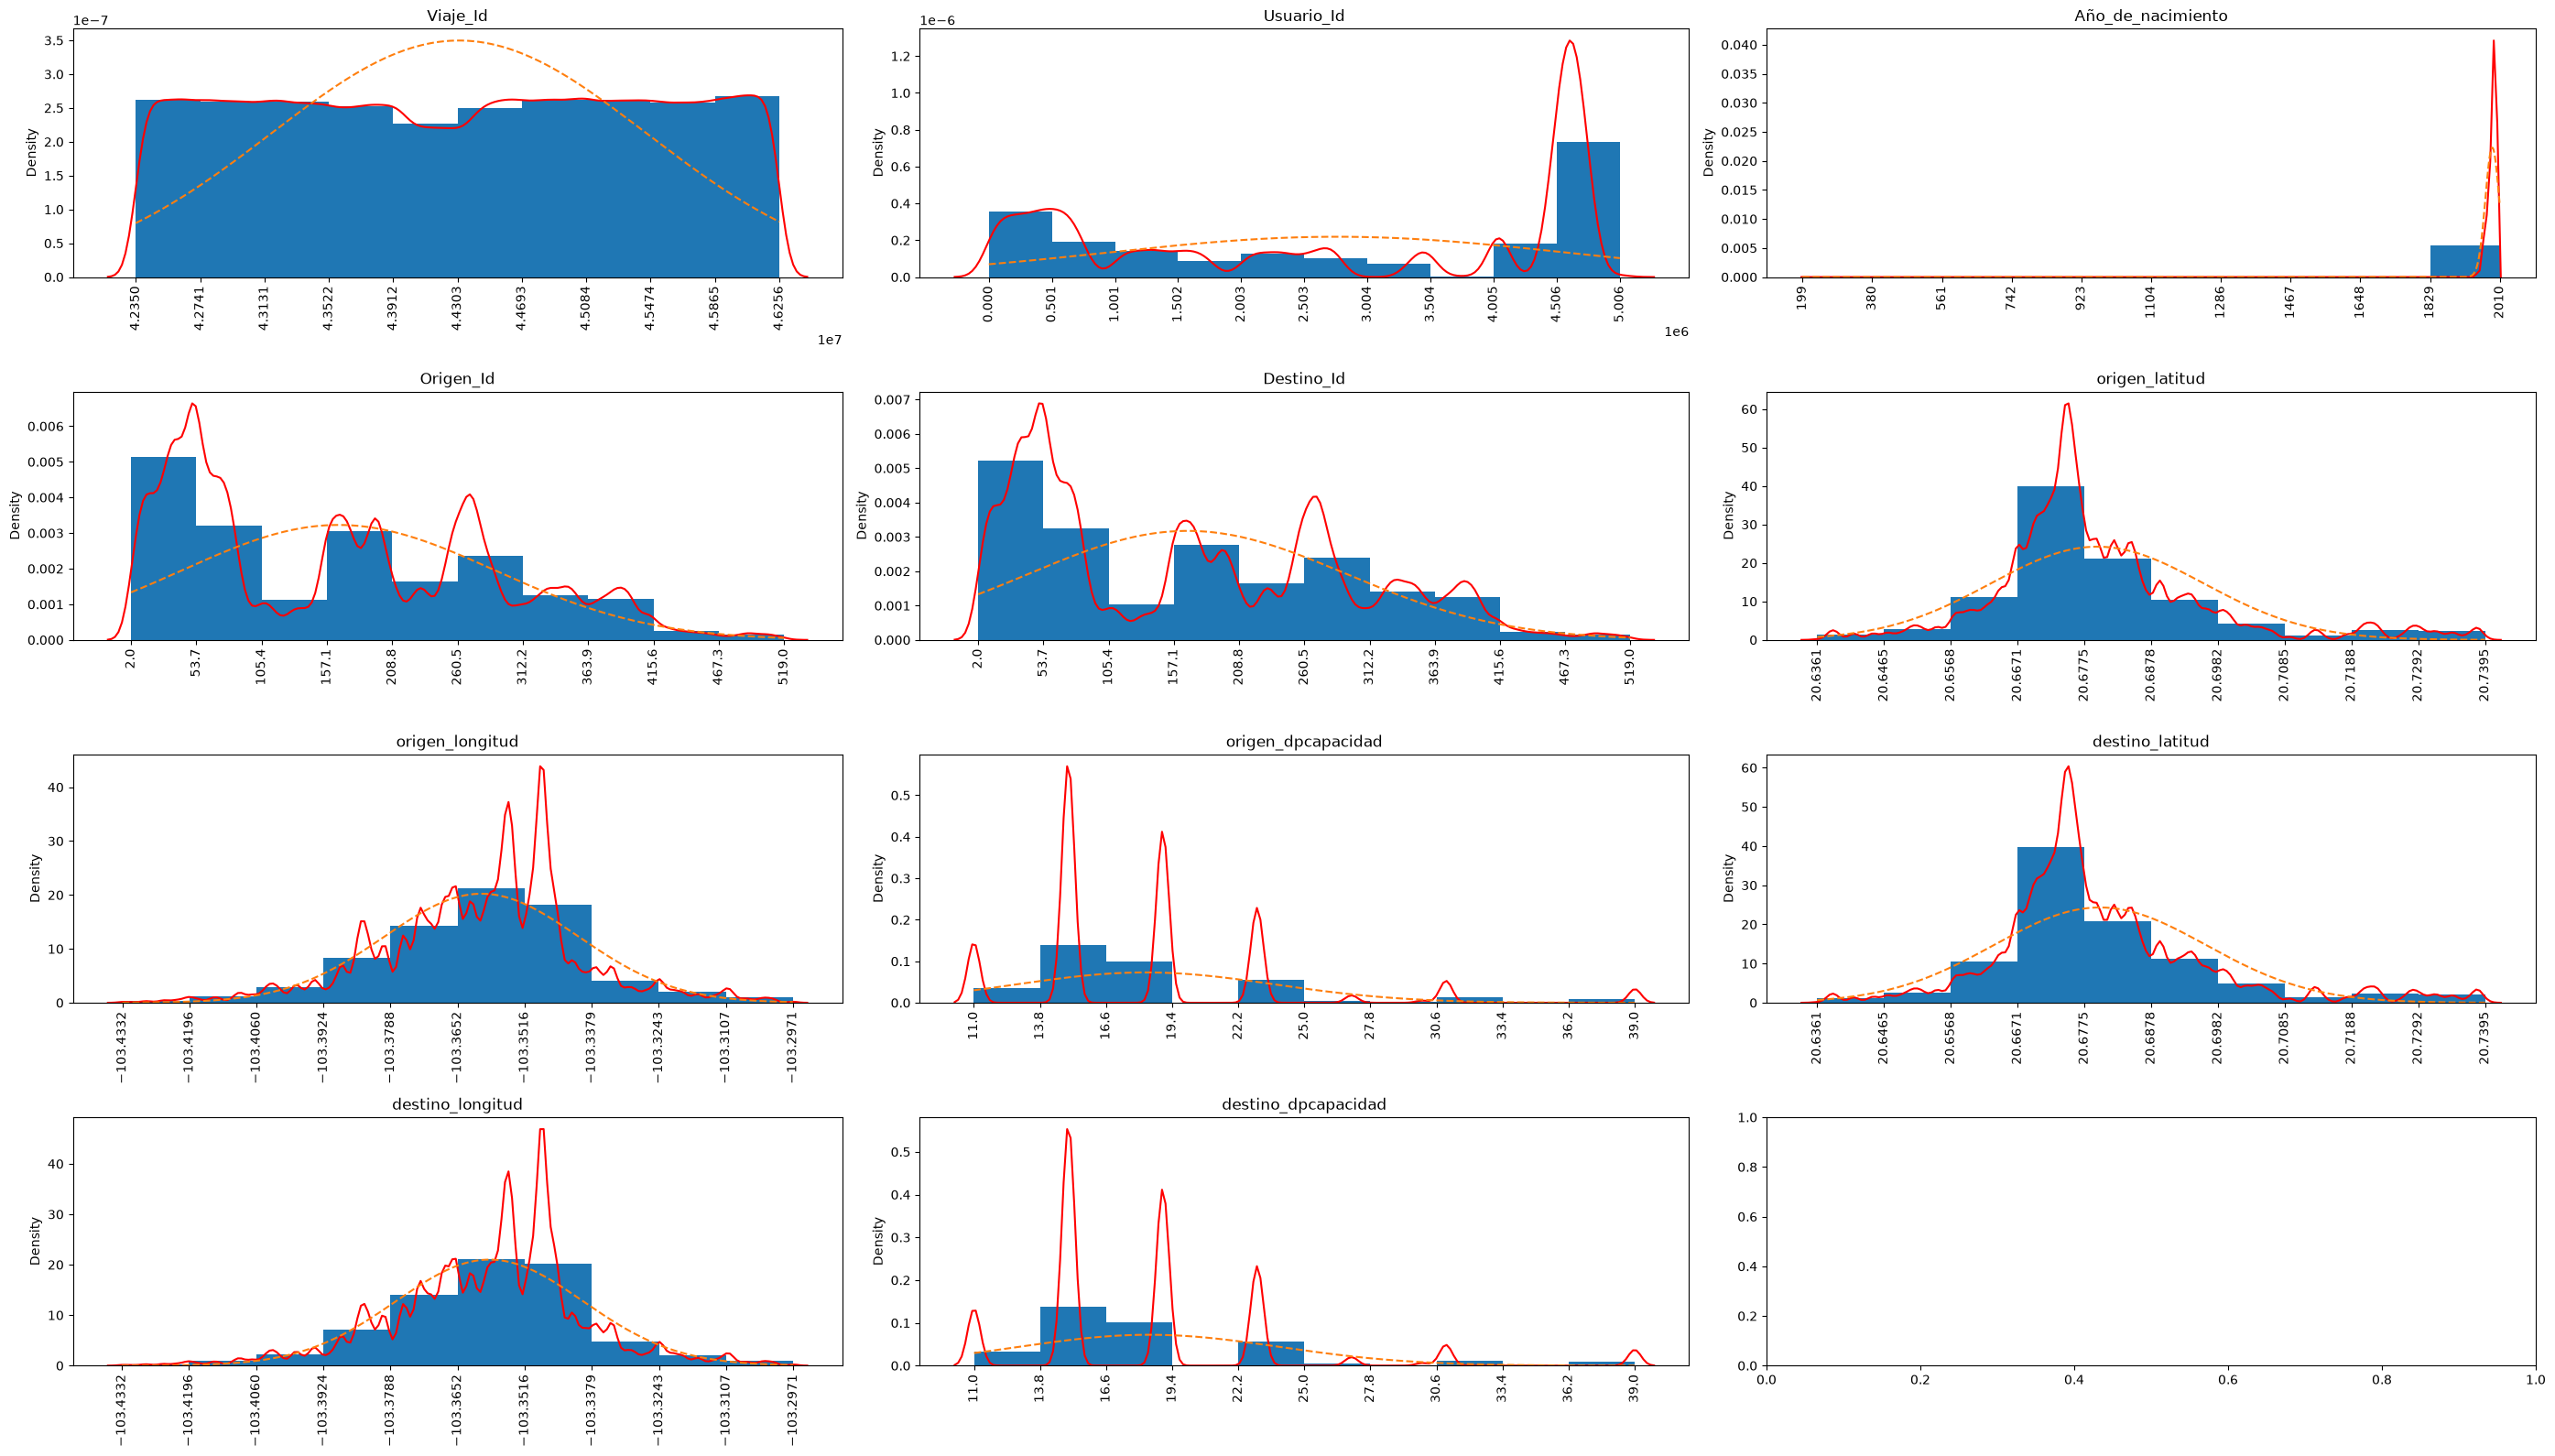


Generamos un boxplot de las variables numericas para revisar outliers...


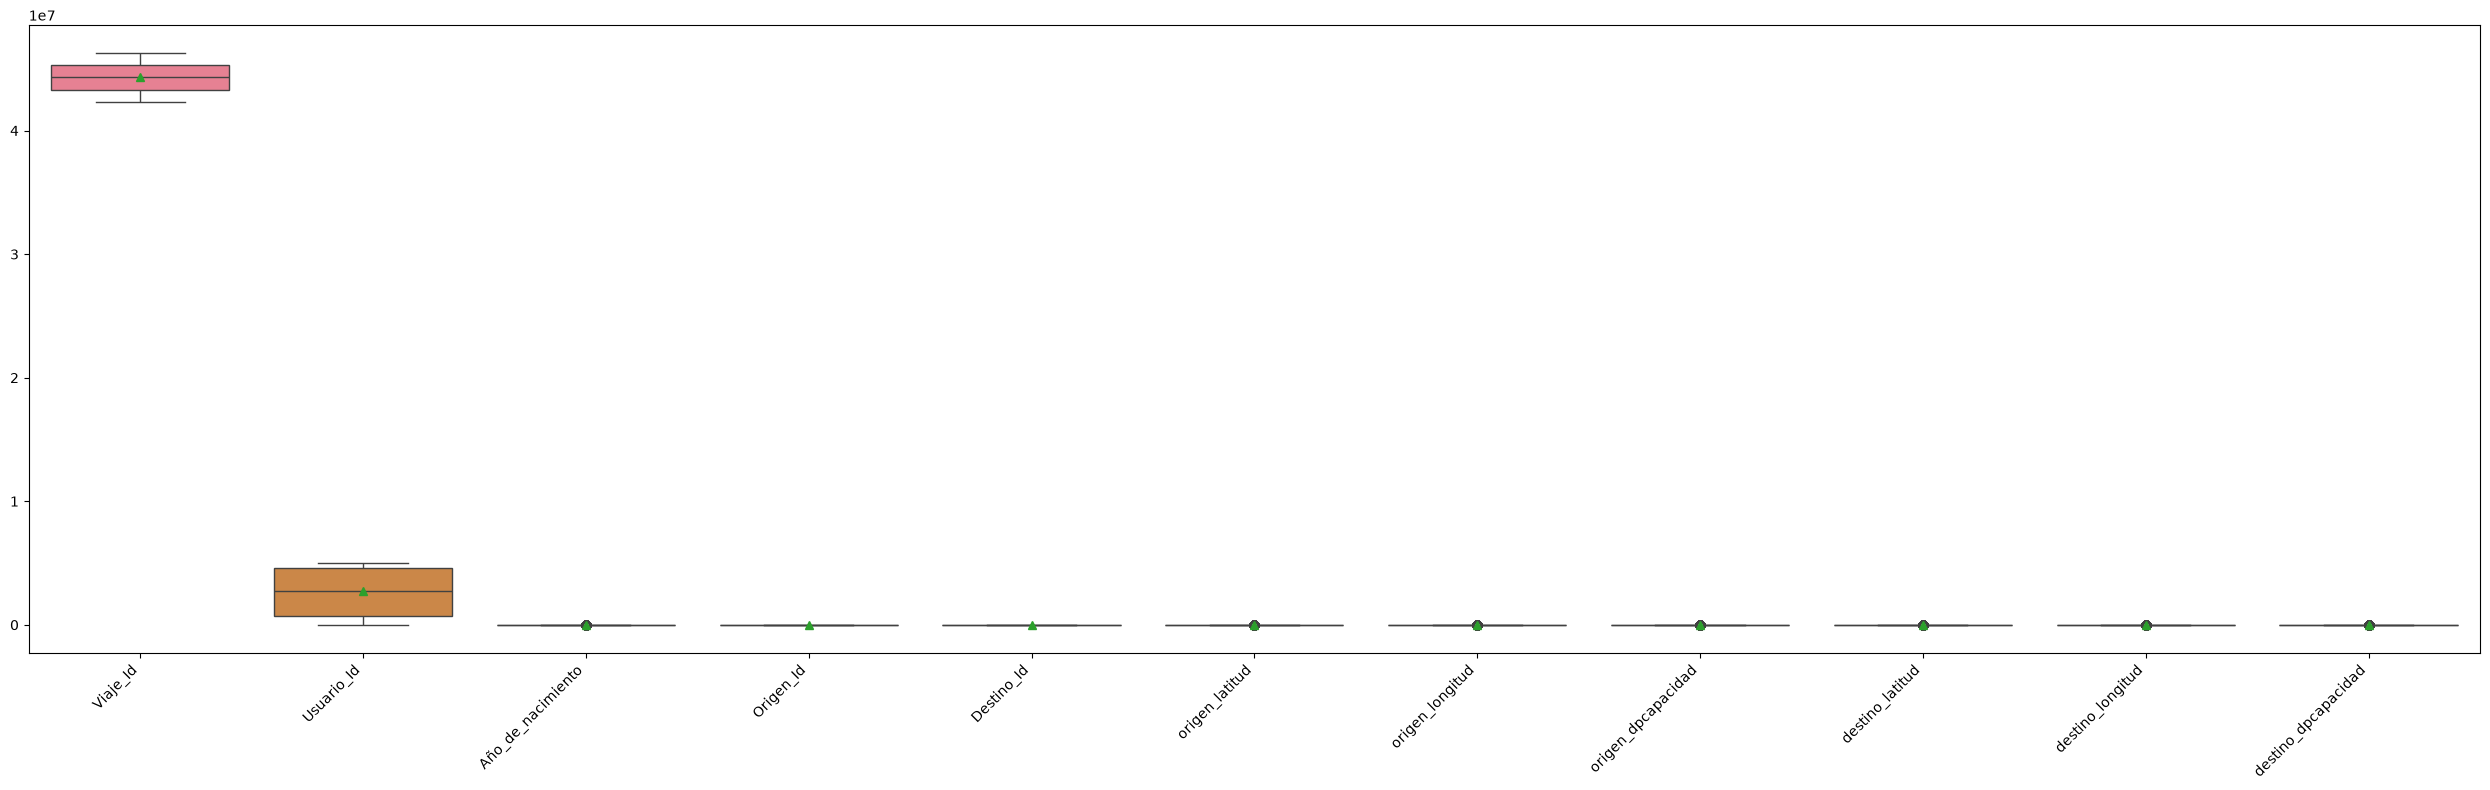

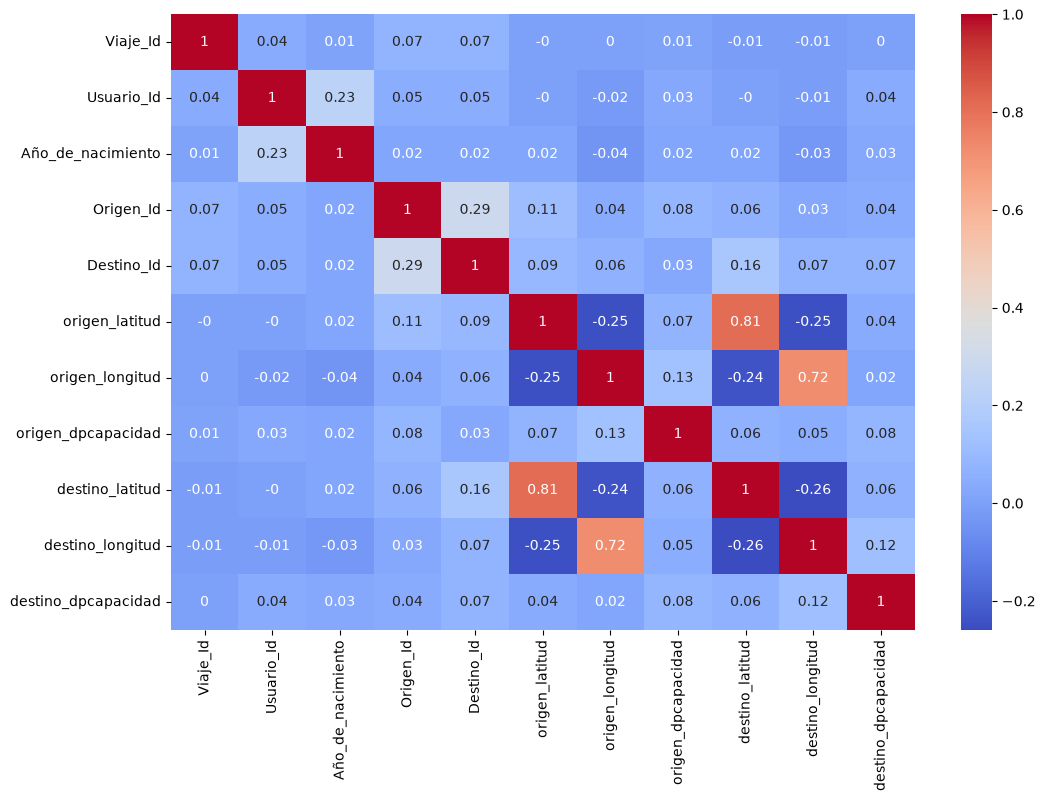

In [5]:
# Get descriptive statistics from the dataframe

# ** Numerical values **
print(f'**************************************************')
print(f'** Datos numericos -- Estadisticas descriptivas **')
print(f'**************************************************')

# Get descriptive statistics from the dataframe adding skewness and kurtosis
desc = df[num_cols].describe()

# Get Skewness (Asymmetry) and Kurtosis
skewness = df.skew(numeric_only=True).to_frame(name='skew').T
kurtosis = df.kurt(numeric_only=True).to_frame(name='kurtosis').T

# Combine in single datagrame using concat method
desc = pd.concat([desc, skewness, kurtosis])

print(f'** Estadisticas descriptivas del dataframe para sus valores numéricos **\n')
display(desc.T)

print(f'\n')

# ** Generating histograms using matplotlib and seaborn **
fig, axes = plt.subplots(4,3, figsize=(28,16))
plt.subplots_adjust(wspace=0.5)

axes = axes.ravel()

for col, ax in zip(num_cols, axes):
  values = df[col].dropna() # Check if this is just 1 value to graphic curve
  
  # Histograma
  n, bins, patches = ax.hist(values, density=True)
  
  if values.nunique() > 1:
    # KDE
    sns.kdeplot(df[col], ax=ax, color='red', warn_singular=False)

    # Parámetros de distribución normal
    mu = df[col].mean()
    sigma = df[col].std()

    # Valores para curva normal
    x_vals = np.linspace(df[col].min(), df[col].max(), 1000)

    normal_ref = norm.pdf(x_vals, loc=mu, scale=sigma)
    # Graficar curva normal
    ax.plot(x_vals, normal_ref, linestyle='--', label='Normal')

  ax.set_xticks(bins) #Draw bins
  ax.set(title=f'{col}', xlabel=None)
  ax.set_xlabel(None)
  # Rotar etiquetas del eje x
  ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

# Create boxplots for numerical values to check their values and outliers
print("\nGeneramos un boxplot de las variables numericas para revisar outliers...")
plt.figure(figsize=(25,8))
sns.boxplot(data=df[num_cols],
            showmeans=True)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Get correlation matrix
corr_matrix = df[num_cols].corr()

print("\n")
plt.figure(figsize = (12, 8))
sns.heatmap(round(corr_matrix,2), annot=True, cmap='coolwarm')
plt.show()

***************************************************
** Datos categoricos - Estadisticas descriptivas **
***************************************************

** Estadisticas descriptivas del dataframe para sus valores categoricos **



,count,unique,top,freq
Genero,3340111,2,M,2428015
Inicio_del_viaje,3362065,2993521,2026-01-30 18:34:12,7
Fin_del_viaje,3362065,2997544,2026-01-07 14:45:51,12
origen_nombre,3360105,469,(GDL-049) Lopez Cotilla / Penitenciaría,75141
destino_nombre,3359942,469,(GDL-049) Lopez Cotilla / Penitenciaría,85405



Frecuencia de las categorias.


Genero
M    2428015
F     912096
Name: count, dtype: int64

Inicio_del_viaje
2026-01-30 18:34:12    7
2026-09-21 19:02:53    7
2026-09-24 18:04:36    7
2026-01-21 08:31:53    6
2026-03-03 18:23:26    6
                      ..
2026-09-30 23:55:59    1
2026-09-30 23:56:38    1
2026-09-30 23:57:23    1
2026-09-30 23:59:32    1
2026-09-30 23:59:48    1
Name: count, Length: 2993521, dtype: int64

Fin_del_viaje
2026-01-07 14:45:51    12
2026-01-30 14:56:22    10
2026-01-06 14:33:30     9
2026-01-02 14:31:00     8
2026-02-17 18:15:21     7
                       ..
2026-10-01 00:07:19     1
2026-10-01 00:14:52     1
2026-09-30 23:59:46     1
2026-10-01 00:06:16     1
2026-10-01 00:13:58     1
Name: count, Length: 2997544, dtype: int64

origen_nombre
(GDL-049) Lopez Cotilla / Penitenciaría          75141
(GDL-198) Av. Alcalde / C. Hospital              51877
(GDL-033) Av. Hidalgo / C. Pedro Loza            51759
(GDL-009) Calz. Federalismo/ C. J. Angulo        46677
(GDL-048) C. Constancio Hernández/ Av. Juaréz    39713
                                                 ...  
(ZPN-102) C. Volcán del Colli/V. del Ajusco        191
(ZPN-100)  C. Popocatépetl / C. Volcán Barú        180
(ZPN-101) C. Volcán Quinceo/C. Ignacio C.          159
(GDL-335) Dionisio Rdgz/González Bocanegra         142
(ZPN-094) Av. V. el Colli / C. V. Paricutín        120
Name: count, Length: 469, dtype: int64

destino_nombre
(GDL-049) Lopez Cotilla / Penitenciaría          85405
(GDL-033) Av. Hidalgo / C. Pedro Loza            59388
(GDL-198) Av. Alcalde / C. Hospital              45101
(GDL-009) Calz. Federalismo/ C. J. Angulo        42496
(GDL-048) C. Constancio Hernández/ Av. Juaréz    40591
                                                 ...  
(ZPN-099) C. Playa Olas / Av. El Colli             174
(ZPN-089) C. Arquitectos/Av. San Luis Gonzaga      153
(ZPN-101) C. Volcán Quinceo/C. Ignacio C.          150
(GDL-335) Dionisio Rdgz/González Bocanegra         139
(ZPN-094) Av. V. el Colli / C. V. Paricutín         95
Name: count, Length: 469, dtype: int64

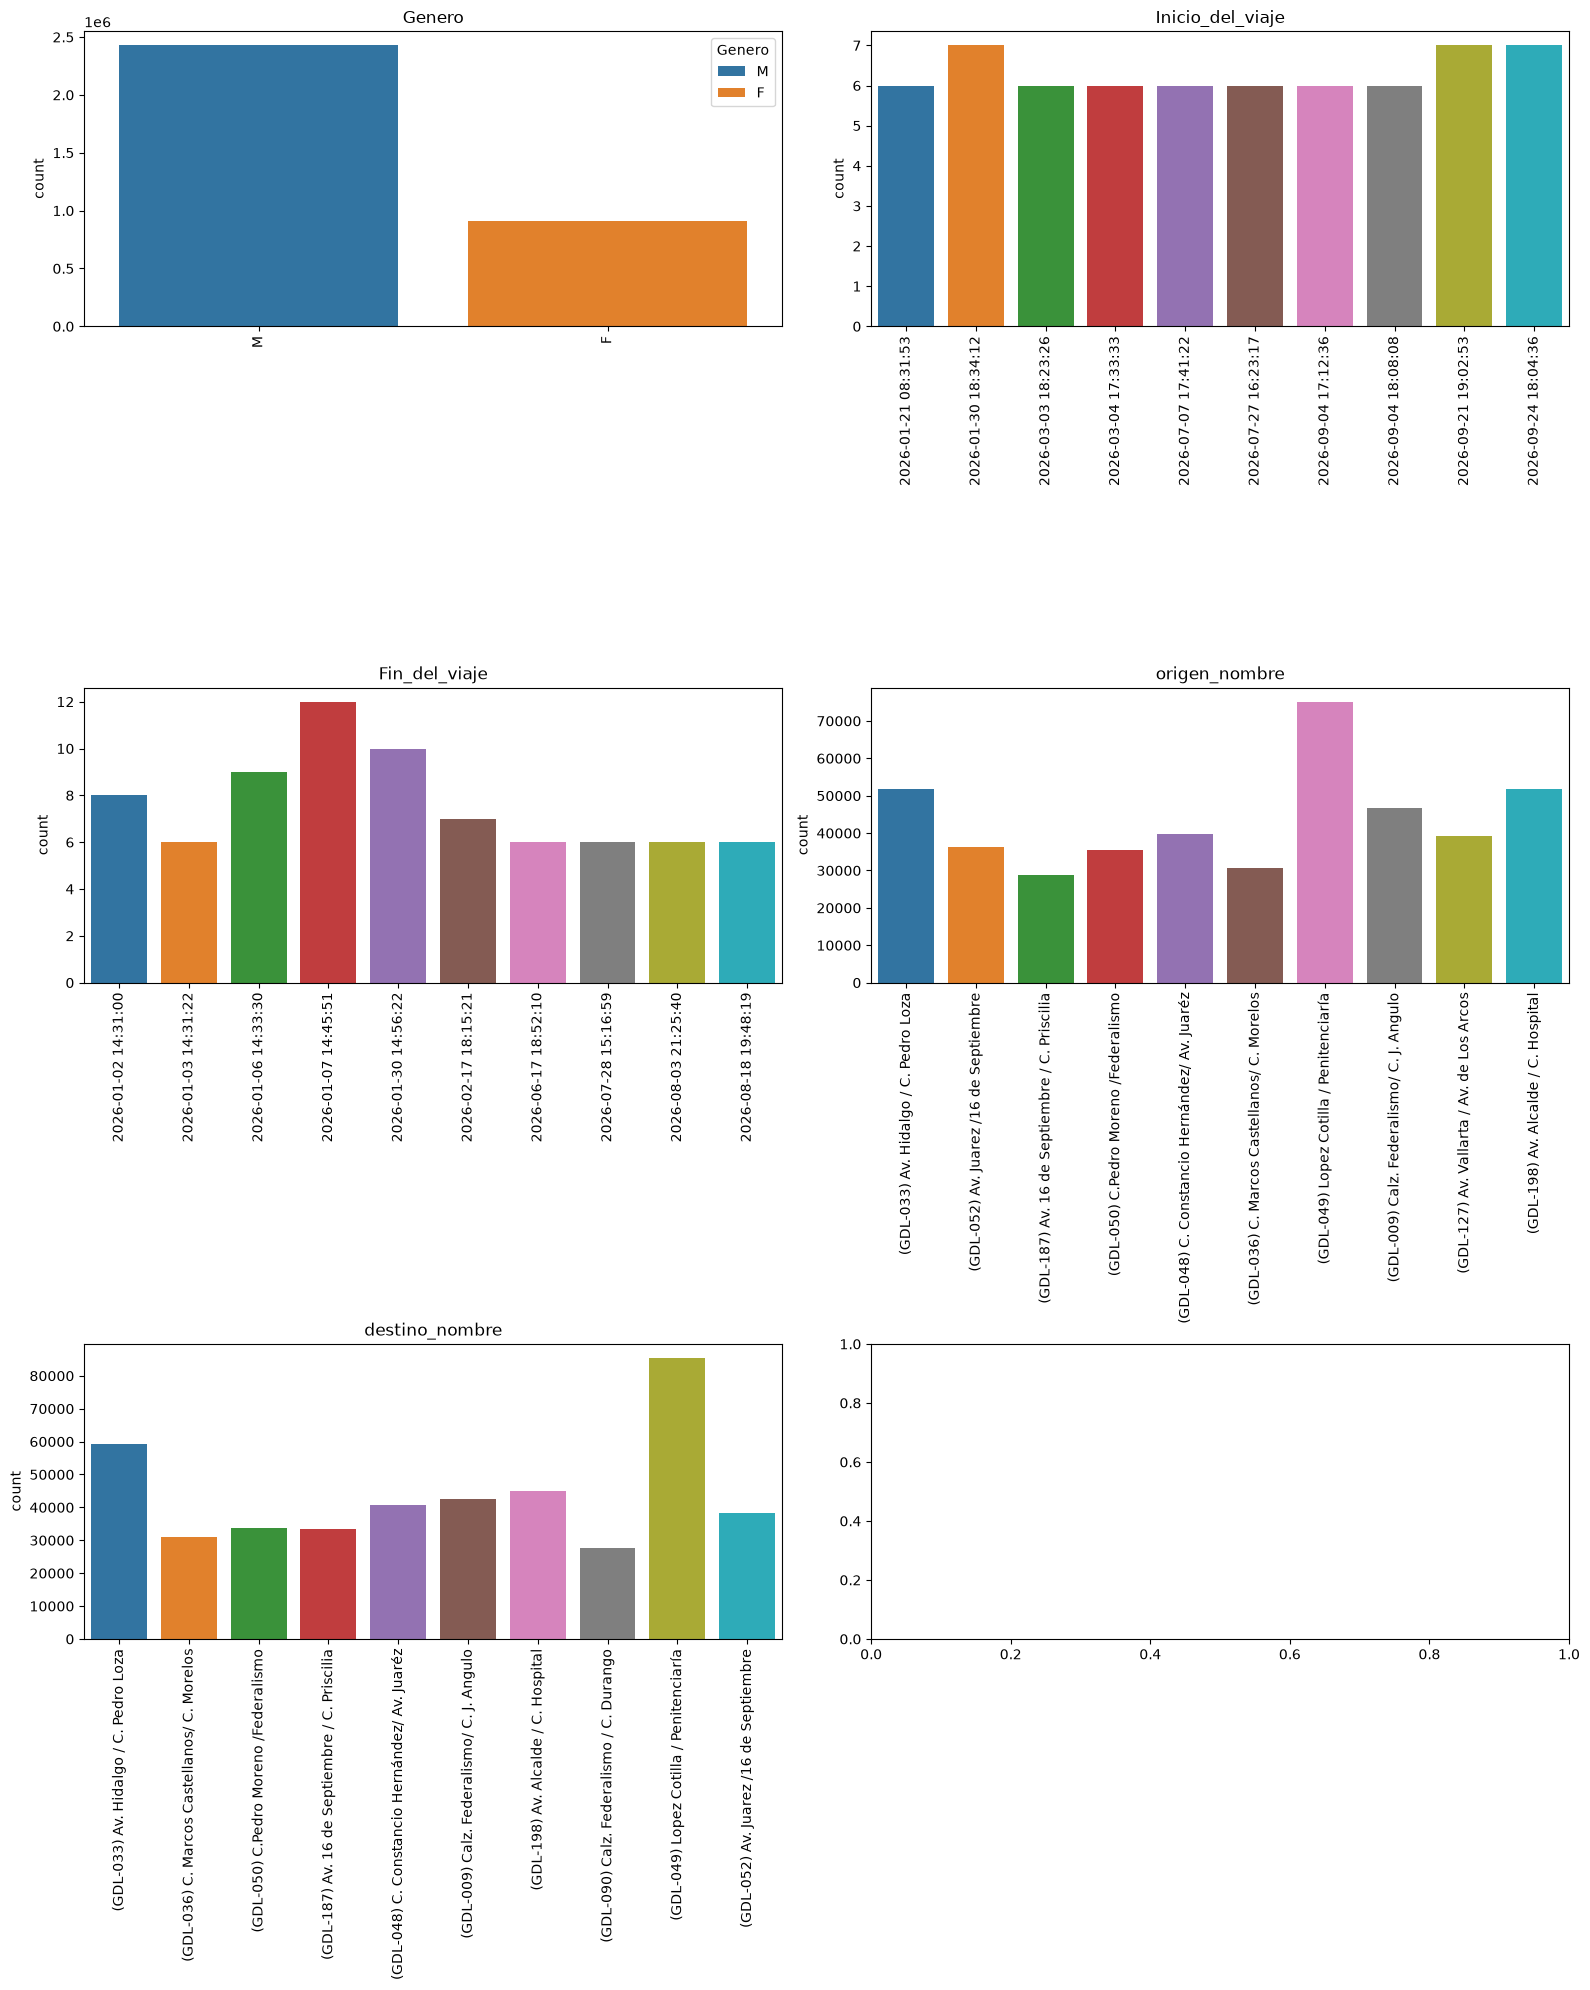

In [6]:
# ** Categorical values **
print(f'***************************************************')
print(f'** Datos categoricos - Estadisticas descriptivas **')
print(f'***************************************************\n')

# ** Categorical values **
print(f'** Estadisticas descriptivas del dataframe para sus valores categoricos **\n')
display(df[cat_cols].describe().T)

print(f'\nFrecuencia de las categorias.')
for col in cat_cols:
  display(df[col].value_counts())

print(f'\n')

fig, axes = plt.subplots(3,2, figsize=(16,20))
plt.subplots_adjust(hspace=2.5)
axes = axes.ravel()
for col, ax in zip(cat_cols, axes):
  # Get cardinality
  cardinality = df[col].nunique()
  #Check if cardinality is highter than 10 to check for frequent values
  if cardinality > 10:
    # Top 10 more frequent values
    top_10 = df[col].value_counts().nlargest(10).index

    # Filter dataframe to verify if data is in top 10
    filtered_df = df[df[col].isin(top_10)]

    #Assign these values to the plot
    xPlot = filtered_df[col]
    huePlot = filtered_df[col]
  else:
    # Not high cardinality, take values normally
    xPlot = df[col]
    huePlot = df[col]
    pass

  sns.countplot(x=xPlot, hue=huePlot, ax=ax) # ---> Seaborn

  ax.set(title=f'{col}', xlabel=None)
  ax.tick_params(axis='x',rotation=90)

plt.tight_layout()
plt.show()